<a href="https://colab.research.google.com/github/MilkySon/-/blob/master/261104E_FINAL_MONSTER_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E_FINAL · BLACKBOX MONSTER RACER 🏁
**Double + Dueling QR-DQN · n-step · PER · NoisyNet · Random Shift · 15 Actions**

300,000 raw frames / RGB-only learned policy / self-contained source / ONNX export.

이 노트북은 **새 모델을 0부터 학습**합니다. 이미 학습된 가중치가 포함되지 않습니다. E15의 final.pt와 호환되지 않습니다. 기존 실험 폴더는 그대로 보존합니다.

1. Colab 런타임 → GPU(T4 이상)를 선택합니다.
2. 아래 설정에서 팀 이름을 입력합니다. 첫 실행은 `monster`, `SEED=42`를 권장합니다.
3. 순서대로 실행합니다. 학습 시간은 GPU·Colab 환경에 따라 달라집니다.
4. 검증으로 모델을 선택한 뒤 공개·보류 평가를 진행합니다. 테스트 점수를 보고 재선택하면 보류 평가가 아닙니다.

PPO/SAC는 별개의 학습법이라 이 Q-agent에 혼합하지 않았습니다. GRU·관측 기반 복귀 보조는 선택형으로 구현했습니다. 기법 수가 많다고 기존 모델보다 높은 점수가 보장되지는 않습니다.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import os, sys, json, subprocess, shutil, hashlib, zipfile, io, base64
TEAM_NAME = 'MyTeam'  # 반드시 실제 등록 팀 이름으로 변경
PRESET = 'monster'   # monster / conservative / qr_only / pixel_recovery / gru
SEED = 42
RESUME = False
STOP_AFTER_CHECKPOINT = False  # 약 50K마다 안전하게 끊어 실행하려면 True
ALLOW_CPU = False
SAVE_VIDEO = False
RUN_NAME = f'E_FINAL_{PRESET}_s{SEED}'
RESULTS = Path('/content/drive/MyDrive/261104E_FINAL_MONSTER')
RUN_DIR = RESULTS / RUN_NAME
RESULTS.mkdir(parents=True, exist_ok=True)
os.environ['SDL_VIDEODRIVER']='dummy'
os.environ['SDL_AUDIODRIVER']='dummy'


Mounted at /content/drive


In [ ]:
# Embedded, version-locked source bundle. No network repository fetch.
SOURCE_B64 = '...'
SOURCE_SHA256 = '75f9d0068a47d1978d0baeb098c9ce322fe8160ff1b41ec1a08ea030bc5afc26'

payload=base64.b64decode(SOURCE_B64)
assert hashlib.sha256(payload).hexdigest()==SOURCE_SHA256
SOURCE=Path('/content')/('monster_src_'+SOURCE_SHA256[:12])
SOURCE.mkdir(exist_ok=True)
with zipfile.ZipFile(io.BytesIO(payload)) as z:
    for name in z.namelist():
        target=(SOURCE/name).resolve()
        assert target.is_relative_to(SOURCE.resolve())
    z.extractall(SOURCE)
os.chdir(SOURCE)
subprocess.run([sys.executable,'-m','pip','install','-q','-r','requirements_monster.txt'],check=True)
import torch
print('Torch:',torch.__version__,'CUDA:',torch.cuda.is_available())
if not torch.cuda.is_available() and not ALLOW_CPU:
    raise RuntimeError('Colab GPU 런타임을 선택하세요. CPU를 사용하려면 ALLOW_CPU=True.')
def run(args, log_name):
    path=RESULTS/log_name
    with path.open('a') as log:
        proc=subprocess.Popen([str(x) for x in args],stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1)
        for line in proc.stdout:
            print(line,end='');log.write(line);log.flush()
        rc=proc.wait()
    if rc:raise RuntimeError(f'명령 실패: {rc}; {path}')
run([sys.executable,'test_monster.py'],'unit_tests.log')


Torch: 2.11.0+cu130 CUDA: True
test_nstep_truncation_and_episode_separation (__main__.Correctness.test_nstep_truncation_and_episode_separation) ... ok
test_quantile_loss_matches_hand_calculation (__main__.Correctness.test_quantile_loss_matches_hand_calculation) ... ok
test_replay_ring_and_probabilities (__main__.Correctness.test_replay_ring_and_probabilities) ... ok
test_shift_preserves_temporal_offsets (__main__.Correctness.test_shift_preserves_temporal_offsets) ... ok
test_three_step_discount (__main__.Correctness.test_three_step_discount) ... ok
test_training_variants_and_noise_eval (__main__.Correctness.test_training_variants_and_noise_eval) ... ok

----------------------------------------------------------------------
Ran 6 tests in 5.851s

OK


## 학습 — 원본 30만 프레임
`RESUME=True`는 이 노트북이 만든 같은 run의 `latest.pt`에만 사용합니다. replay와 RNG도 복원합니다. 강제 종료로 저장하지 못한 구간은 복원할 수 없습니다.

전체 노트북 다시 실행 시 완성된 run은 재학습하지 않습니다. 설정을 바꾸려면 새 RUN_NAME을 사용하세요.


In [ ]:
assert PRESET in ['monster','conservative','qr_only','pixel_recovery','gru']
config=json.loads((SOURCE/'configs'/f'{PRESET}.json').read_text())
config['seed']=SEED
CONFIG=SOURCE/'active_config.json'
CONFIG.write_text(json.dumps(config,indent=2))
if (RUN_DIR/'config.json').exists():
    assert json.loads((RUN_DIR/'config.json').read_text())==config, '설정이 다릅니다. 새 RUN_NAME을 사용하세요.'
completed=False
if (RUN_DIR/'final.pt').exists():
    ck=torch.load(RUN_DIR/'final.pt',map_location='cpu',weights_only=False)
    completed=ck['frames']==config['budget']
    del ck
if completed:
    print('완료된 학습 재사용:',RUN_DIR)
else:
    cmd=[sys.executable,'train.py','--agent','monster','--config',CONFIG,'--run-dir',RUN_DIR]
    if RESUME:cmd.append('--resume')
    if STOP_AFTER_CHECKPOINT:cmd.append('--stop-after-checkpoint')
    run(cmd,f'{RUN_NAME}_training.log')
ck=torch.load(RUN_DIR/'final.pt',map_location='cpu',weights_only=False)
print('Consumed raw frames:',ck['frames'])
assert ck['frames']==config['budget'], '안전 중단되었습니다. RESUME=True로 다시 학습 셀을 실행하세요.'
del ck


/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
frames=8247/300000 episode=10 return=-33.1 updates=562
frames=18247/300000 episode=20 return=63.4 updates=3062
frames=27036/300000 episode=30 return=-81.9 updates=5261
frames=36481/300000 episode=40 return=3.3 updates=7623
frames=45517/300000 episode=50 return=71.1 updates=9883
VALIDATION 50517: 535.0 ± 199.3; best=535.0
frames=55517/300000 episode=60 return=276.9 updates=12383
frames=65466/300000 episode=70 return=559.9 updates=14871
frames=75466/300000 episode=80 return=261.3 updates=17371
frames=85466/300000 episode=90 return=532.8 updates=19871
frames=95466/300000 episode=100 return=746.6 updates=22371
VALIDATION 100466: 52

## 검증용 트랙에서 checkpoint 비교
아래 그래프는 탐험이 있는 train return과 탐험이 없는 validation을 구분합니다. `best.pt` 선택에는 500–509만 사용됩니다. E15의 best/final 차이를 놓치지 않도록 마지막 결과도 별도로 표시합니다.


[
  {
    "frames": 300000,
    "checkpoint": "step_300000.pt",
    "mean": 856.4787904485063,
    "std": 80.24800973481432,
    "minimum": 653.1645569620099,
    "below700": 1,
    "bottom20_mean": 710.544542631938
  },
  {
    "frames": 250816,
    "checkpoint": "step_250816.pt",
    "mean": 854.2655414923413,
    "std": 66.02008136113871,
    "minimum": 695.0530035335513,
    "below700": 1,
    "bottom20_mean": 745.687036883822
  },
  {
    "frames": 150281,
    "checkpoint": "step_150281.pt",
    "mean": 852.3792015613753,
    "std": 54.338326602809055,
    "minimum": 736.4779874213657,
    "below700": 0,
    "bottom20_mean": 776.432973643783
  },
  {
    "frames": 200694,
    "checkpoint": "step_200694.pt",
    "mean": 845.873162078747,
    "std": 105.60204693025446,
    "minimum": 545.5696202531478,
    "below700": 1,
    "bottom20_mean": 674.0426717617836
  },
  {
    "frames": 50517,
    "checkpoint": "step_50517.pt",
    "mean": 535.049939920545,
    "std": 199.32600280319892,

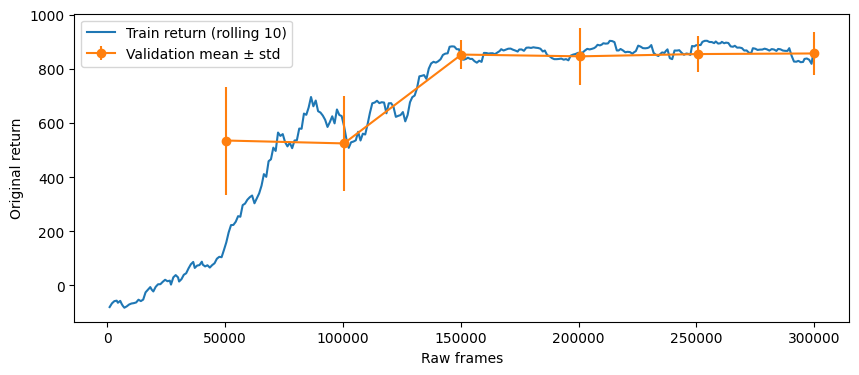

,frames,checkpoint,mean,std,minimum,below700,bottom20_mean
0,300000,step_300000.pt,856.478790,80.248010,653.164557,1,710.544543
1,250816,step_250816.pt,854.265541,66.020081,695.053004,1,745.687037
2,150281,step_150281.pt,852.379202,54.338327,736.477987,0,776.432974
3,200694,step_200694.pt,845.873162,105.602047,545.569620,1,674.042672
4,50517,step_50517.pt,535.049940,199.326003,148.427673,8,238.260659
5,100466,step_100466.pt,524.423322,175.308335,263.957597,9,265.593893


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
run([sys.executable,'select_checkpoint.py','--run-dir',RUN_DIR],f'{RUN_NAME}_selection.log')
tr=pd.read_csv(RUN_DIR/'train.csv'); ev=pd.read_csv(RUN_DIR/'eval.csv')
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(tr.frames,tr.return_.rolling(10,min_periods=1).mean(),label='Train return (rolling 10)')
ax.errorbar(ev.frames,ev.score,yerr=ev['std'],label='Validation mean ± std',fmt='o-')
ax.set(xlabel='Raw frames',ylabel='Original return');ax.legend();plt.show()
display(pd.read_csv(RUN_DIR/'checkpoint_comparison.csv'))
SELECTED=RUN_DIR/'best.pt'  # validation 최고 평균. 보류 평가를 보고 바꾸지 마세요.


## ONNX 생성 + 실제 행동 일치 검증
입력 RGB → gray/resize/stack → Q-network → 행동 선택/15행동 매핑이 모두 ONNX 안에 들어갑니다. 규칙으로 복귀 조향을 덮어쓰지 않습니다. 모델이 100MB를 넘거나 행동이 일치하지 않으면 중단합니다.


In [ ]:
assert TEAM_NAME!='MyTeam' and TEAM_NAME.strip(), '첫 설정 셀에서 실제 팀 이름을 입력하세요.'
assert not any(ch in TEAM_NAME for ch in r'\/:*?"<>|'), '팀 이름의 금지 문자를 제거하세요.'
MODEL=RUN_DIR/f'{TEAM_NAME}_EFINAL_{PRESET}_fs4_stack4_img84.onnx'
run([sys.executable,'monster_runner.py','export','--ckpt',SELECTED,'--out',MODEL],f'{RUN_NAME}_export.log')


AssertionError: 첫 설정 셀에서 실제 팀 이름을 입력하세요.

## 공개 비교와 최종 보류 평가
1000–1009: E15 비교용 / 1000–1019: 공개 20개 보고 / 3000–3029: 최종 보류 30개.

보류 트랙을 이미 사용했다면 실행 전에 범위를 바꾸세요. 아래 점수는 교수자의 비공개 트랙 점수를 보장하지 않습니다. 공개 10개와 20개를 서로 다른 조건으로 비교하지 마세요.


In [ ]:
REPORTS=RUN_DIR/'reports';REPORTS.mkdir(exist_ok=True)
MODEL_HASH=hashlib.sha256(MODEL.read_bytes()).hexdigest()
for name,seed_range in [('public20','1000-1019'),('holdout30','3000-3029')]:
    report=REPORTS/f'{name}.json'
    if report.exists():
        saved=json.loads(report.read_text())
        assert saved.get('onnx_sha256')==MODEL_HASH, '다른 모델의 평가입니다. 새 결과 폴더로 평가하세요.'
        print('이미 저장된 평가 재사용:',report)
    else:
        run([sys.executable,'check_submission.py','--onnx',MODEL,'--seeds',seed_range,'--json',report],f'{RUN_NAME}_official_eval.log')
        saved=json.loads(report.read_text());saved['onnx_sha256']=MODEL_HASH
        report.write_text(json.dumps(saved,indent=2))
rows=[]
for name in ['public20','holdout30']:
    obj=json.loads((REPORTS/f'{name}.json').read_text());assert obj['ok']
    v=obj['returns'];rows.append(dict(split=name,mean=obj['mean'],std=obj['std'],min=min(v),below700=sum(x<700 for x in v)))
    if name=='public20':
        import numpy as np
        rows.append(dict(split='E15 matched 1000–1009',mean=np.mean(v[:10]),std=np.std(v[:10]),min=min(v[:10]),below700=sum(x<700 for x in v[:10])))
display(pd.DataFrame(rows))
pd.DataFrame(rows).to_csv(REPORTS/'summary.csv',index=False)


## 영상 진단 (선택)
정확한 역주행·복귀 성공 여부는 영상으로 확인하세요. 픽셀 proxy는 wheel contact 정답이 아닙니다. 기본 결과에서 측정되지 않은 역주행을 0으로 적지 않습니다.


In [ ]:
if SAVE_VIDEO:
    run([sys.executable,'monster_runner.py','eval','--ckpt',SELECTED,'--seeds','1000',
         '--out',REPORTS/'visual_diagnostics.json','--video-dir',RUN_DIR/'videos'],f'{RUN_NAME}_video.log')
    from IPython.display import Video
    display(Video(str(RUN_DIR/'videos'/'seed_1000.mp4'),embed=True,width=480))
else:
    print('영상은 SAVE_VIDEO=True로 활성화할 수 있습니다.')


## 최종 제출 ZIP
검증된 ONNX와 **그 ONNX에 대응하는 checkpoint**를 담습니다. 큰 replay 복구 파일은 제외합니다. 제출 전에 팀 이름과 교수자 제출 요건을 확인하세요.


In [ ]:
BUNDLE=RESULTS/f'{TEAM_NAME}_{RUN_NAME}_submission.zip'
ck=torch.load(SELECTED,map_location='cpu',weights_only=False)
manifest=dict(selected_checkpoint=str(SELECTED),training_frames=ck['frames'],run_id=ck['run_id'],
              onnx_sha256=hashlib.sha256(MODEL.read_bytes()).hexdigest(),source_bundle_sha256=SOURCE_SHA256)
del ck
with zipfile.ZipFile(BUNDLE,'w',zipfile.ZIP_DEFLATED) as z:
    for p in SOURCE.rglob('*'):
        if p.is_file() and '__pycache__' not in p.parts:
            z.write(p,str(Path('source')/p.relative_to(SOURCE)))
    z.write(SELECTED,'run/best.pt');z.write(MODEL,MODEL.name)
    for p in RUN_DIR.rglob('*'):
        if p.is_file() and p.suffix in ['.json','.csv','.txt']:
            z.write(p,str(Path('run')/p.relative_to(RUN_DIR)))
    for p in RESULTS.glob(f'{RUN_NAME}_*.log'):
        z.write(p,str(Path('logs')/p.name))
    z.writestr('submission_manifest.json',json.dumps(manifest,indent=2))
    reproduce=chr(10).join(['cd source',
       'pip install -r requirements_monster.txt',
       'python train.py --agent monster --config active_config.json --run-dir ../reproduced_run'])
    z.writestr('REPRODUCE.txt',reproduce)

print('제출 파일:',BUNDLE)
print('학습 결과/로그:',RUN_DIR)
from google.colab import files
files.download(str(BUNDLE))
